# Курсовая работа по предмету «Численные методы»

**Тема:** «Применение кокригинга для выявления загруженных участков дорожной сети».

**Задание:** получить данные структуре улично-дорожной сети и об интенсивности движения в выбранном населенном пункте из открытых источников. Применить алгоритм кокригинга для выявления самого загруженного участка улично-дорожной сети с учетом сведений о поворотах. Оценить точность полученного результата.

Основная переменная $Z(x)$ - количество автомобилей, прошедших через перекресток за 14 часов. Измерения есть только для части перекрестков, поэтому остальные значения нужно восстановить.

Для кокригинга также нужны сведения о дорожной сети. Сначала рассмотрим два способа описать повороты:
> Изначально он был один - число возможных поворотов, но он не дал преимущества перед ординарным кригингом, поэтому я решила рассмотреть характеристику поворотов, более похожую на представленную в статье Вячеслава

- $T_1(x)$ - число геометрически возможных поворотов на перекрестке;
- $T_2(x)$ - угловая посредническая центральность, то есть характеристика того, как часто перекресток встречается на маршрутах с небольшими суммарными угловыми отклонениями.

В ходе работы проверим, какой из признаков лучше подходит в качестве вспомогательной переменной. Для этого сравним ошибки обычного кригинга и кокригинга с каждым из признаков.

> Все формулы использовала из своих математических выкладок (из pdf) по статье С.М. Кошеля, О.Р. Мусина и книги "Mining Geostatistics"

В конце восстановим интенсивность для всех выделенных перекрестков OSM, нанесем результаты на карту и отдельно покажем наиболее загруженные перекрестки. Точность проверим на перекрестках со скрытыми измерениями. Посчитаем абсолютные и относительные погрешности, MAE, MSE и RMSE. Для относительной оценки также используем MAPE и WAPE. Отдельно рассмотрим расчетную дисперсию ошибки кокригинга.

## Исходные данные и дорожный граф

In [1]:
import itertools
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from matplotlib.collections import LineCollection
from pyproj import Transformer
from scipy.optimize import minimize_scalar
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

# все исходные файлы и результаты храним в папке data
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
TMC_FILE = DATA_DIR / "tmc_most_recent_summary_data.csv"
GRAPH_FILE = DATA_DIR / "toronto_driving.graphml"

# фиксируем случайность, чтобы результаты можно было повторить
SEED = 42
# берем относительно новые измерения и сопоставляем их с OSM не дальше 45 м
MIN_COUNT_DATE = "2024-01-01"
MAX_MATCH_METERS = 45
# сколько ближайших измерений Z и значений T используем для прогноза
K_Z = 16
K_T = 20

# сколько начальных и конечных точек выбираем для расчета центральности
N_ORIGINS = 100
N_DESTINATIONS = 60
LENGTH_PENALTY = 0.1

# параметры внутренней проверки качества
REPEATS = 2
VALIDATION_SIZE = 500

In [2]:
# загружаем измерения интенсивности и оставляем нужные столбцы
tmc = pd.read_csv(TMC_FILE, low_memory=False)
counts = pd.DataFrame({
    "latitude": pd.to_numeric(tmc["latitude"], errors="coerce"),
    "longitude": pd.to_numeric(tmc["longitude"], errors="coerce"),
    "date": pd.to_datetime(tmc["latest_count_date"], errors="coerce"),
    "Z": pd.to_numeric(tmc["total_vehicle"], errors="coerce"),
    "duration": pd.to_numeric(tmc["count_duration"], errors="coerce"),
})
# удаляем пропуски, берем положительные значения за 14 часов начиная с 2024 года
counts = counts.dropna()
counts = counts.loc[
    (counts["date"] >= MIN_COUNT_DATE)
    & (counts["duration"] == 14)
    & (counts["Z"] > 0)
    & counts["latitude"].between(43.55, 43.90)
    & counts["longitude"].between(-80.0, -79.1)
].sort_values("date").reset_index(drop=True)

# проверяем, что после фильтрации осталось достаточно измерений
assert len(counts) > 50
assert (counts["duration"] == 14).all() and (counts["Z"] > 0).all()
print("Измерений за 14 часов:", len(counts))
print("Даты:", counts["date"].min().date(), "-", counts["date"].max().date())

Измерений за 14 часов: 2452
Даты: 2024-01-16 - 2026-10-28


In [3]:
# если граф уже скачан, используем сохраненный файл
if GRAPH_FILE.exists():
    G = ox.load_graphml(GRAPH_FILE)
else:
    G = ox.graph_from_place("Toronto, Ontario, Canada", network_type="drive", simplify=True)
    ox.save_graphml(G, GRAPH_FILE)

# переводим граф в метрическую систему координат, чтобы расстояния были в метрах
G = ox.project_graph(G)

In [4]:
# ищем потенциальные перекрестки по числу соседей
# т.к. граф направленный, то у двусторонней дороги будет потомок=предшественник
# => берем хотя бы 3 соседа

node_ids = [v for v in G.nodes
            if len(set(G.predecessors(v)) | set(G.successors(v))) >= 3]
X_all = np.array([[G.nodes[v]["x"], G.nodes[v]["y"]] for v in node_ids])
assert len(node_ids) > 0 and np.isfinite(X_all).all()
print("Узлов OSM:", len(G.nodes), "перекрестков:", len(node_ids))

Узлов OSM: 27429 перекрестков: 22354


## Вспомогательные данные о поворотах

### $T_1(x)$ - число возможных поворотов

Сначала оценим количество поворотов непосредственно на каждом перекрестке. Считаем пары входящих и исходящих направлений с углом изменения движения от $30^\circ$ до $150^\circ$. Движение прямо и развороты не учитываем.

$$T_1(x)=\sum_{m\in M(x)}\mathbf{1}\{30^\circ\leq\alpha_m\leq150^\circ\}.$$

In [5]:
road_edges = {}
# пробегаем по всем ребрам u->v
for u, v, data in G.edges(data=True):
    length = float(data.get("length", 0))
    # не учитываем петли
    if (u != v and np.isfinite(length) and length > 0 and
        # сохраняем в road_edges только самые короткие ребра между u->v
        ((u, v) not in road_edges or length < road_edges[u, v]["length"])):
            road_edges[u, v] = data


def tangents(u, v, data):
    """возвращает 2 вектора направления: в начале движения и в конце"""
    start = np.array([G.nodes[u]["x"], G.nodes[u]["y"]])
    end = np.array([G.nodes[v]["x"], G.nodes[v]["y"]])

    # учитываем геометрию ребра (дорога может быть ломаной)
    # если в osm-карте она не указана, предполагаем, что участок прямой
    geometry = data.get("geometry")
    points = np.asarray(geometry.coords) if hasattr(geometry, "coords") else np.array([start, end])

    # проверяем, правильно ли указано направление, в случае чего - разворачиваем вектор
    if np.linalg.norm(points[-1] - start) < np.linalg.norm(points[0] - start):
        points = points[::-1]

    # берем векторы разностей между соседними точками участка, игнорируя нулевые
    steps = np.diff(points, axis=0)
    steps = steps[np.linalg.norm(steps, axis=1) > 1e-8]
    if len(steps) == 0:
        steps = np.array([end - start])

    # нормируем
    return (
        steps[0] / np.linalg.norm(steps[0]),
        steps[-1] / np.linalg.norm(steps[-1])
    )


def count_turns(v):
    """возвращает число возможных поворотов на перекрестке"""
    total = 0

    # перебираем входящие дороги u->v из road_edges
    for u in set(G.predecessors(v)):
        if (u, v) not in road_edges:
            continue

        # смотрим направление u->v
        direction_in = tangents(u, v, road_edges[u, v])[1]

        # перебираем выходящие дороги v->w из road_edges
        # (маневр с разворотом u->v->u не считаем)
        for w in set(G.successors(v)):
            if u == w or (v, w) not in road_edges:
                continue

            # смотрим направление v->w
            direction_out = tangents(v, w, road_edges[v, w])[0]

            # скалярное произведение = cos угла
            angle = np.degrees(np.arccos(np.clip(direction_in @ direction_out, -1, 1)))
            total += 30 <= angle <= 150
    return total


# считаем число поворотов для каждого перекрестка
T_turn = np.array([count_turns(v) for v in node_ids], dtype=float)
print("Распределение числа поворотов:")
print(pd.Series(T_turn).value_counts().sort_index())

Распределение числа поворотов:
0.0      1349
1.0       959
2.0      3256
3.0       399
4.0     12641
5.0        62
6.0       387
7.0         8
8.0      3246
9.0        15
10.0       24
11.0        4
12.0        1
13.0        1
16.0        2
Name: count, dtype: int64


In [6]:
# перевод координат из системы долгота-широта в координаты osm
transformer = Transformer.from_crs(
    "EPSG:4326",
    G.graph["crs"],
    always_xy=True
)
x, y = transformer.transform(counts["longitude"].to_numpy(),
                             counts["latitude"].to_numpy())

# находим ближайший перекресток
distances, nearest = cKDTree(X_all).query(np.column_stack([x, y]))
# сохраняем индекс ближайшего узла и расстояние до него
counts["node_index"] = nearest
counts["distance_m"] = distances

# сопоставляем с osm-перекрестком
# если несколько измерений попали в один узел, оставляем ближайшее к нему
matched = counts.loc[counts["distance_m"] <= MAX_MATCH_METERS]
matched = matched.sort_values("distance_m").drop_duplicates("node_index")

# node_observed - индексы перекрестков, где есть измерения
# Z_observed - соотв. значения интенсивности
node_observed = matched["node_index"].to_numpy(int)
Z_observed = matched["Z"].to_numpy(float)

# делим на обучение и проверку
rng = np.random.default_rng(SEED)
order = rng.permutation(len(Z_observed))
n_train = int(0.75 * len(order))
train_idx, test_idx = order[:n_train], order[n_train:]

assert len(node_observed) > 50 and len(np.unique(node_observed)) == len(node_observed)
assert np.isfinite(Z_observed).all() and (Z_observed > 0).all()
assert (matched["distance_m"] <= MAX_MATCH_METERS).all()
print("Измерений после сопоставления:", len(Z_observed))
print("Обучение:", len(train_idx), "контроль:", len(test_idx))
print("Максимальная дистанция сопоставления:", round(matched["distance_m"].max(), 1), "м")

Измерений после сопоставления: 2359
Обучение: 1769 контроль: 590
Максимальная дистанция сопоставления: 40.5 м


### $T_2(x)$ - угловая центральность

Второй вариант учитывает не только геометрию самого перекрестка, но и его положение в дорожной сети. Для этого построим маршруты с минимальной угловой стоимостью:

$$L(P)=\sum_{m\in P}\frac{2\alpha_m}{\pi}+\mu\,\ell(P),\qquad \mu=0.1\ \text{на км},$$

где $\alpha_m$ - изменение направления в радианах, $\ell(P)$ - длина маршрута в километрах. Небольшой штраф за длину нужен, чтобы алгоритм не выбирал слишком длинные объезды только ради меньшего числа поворотов.

Если $R$ - количество успешно построенных маршрутов, а $N(x)$ - число маршрутов, проходящих через перекресток $x$ как через промежуточную точку, то используем признак:

$$T_2(x)=\ln\!\left(1+1000\frac{N(x)}{R}\right).$$

Центральность рассчитывается приближенно, по выборке маршрутов.

In [7]:
# сопоставляем перекрестку его порядковый номер
nodes = list(G.nodes)
node_pos = {v: i for i, v in enumerate(nodes)}

# segments будет хранить направленные участки:
#     [0] - начало,
#     [1] - конец,
#     [2] - длина,
#     [3] - направление_в_начале,
#     [4] - направление_в_конце
segments = []
incoming = defaultdict(list) # индексы участков, заканчивающихся в v
outgoing = defaultdict(list) # индексы участков, начинающихся в v

for (u, v), data in road_edges.items():
    first, last = tangents(u, v, data)
    i = len(segments)
    segments.append((u, v, float(data["length"]), first, last))
    incoming[v].append(i)
    outgoing[u].append(i)

n_segments = len(segments)
n_nodes = len(nodes)
rows, cols, weights = [], [], []

# угловая стоимость перехода между направленными участками
for v in nodes:
    # как и в count_turns высчитываем угол между участками
    # но оставляем в радианах
    for i in incoming[v]:
        u = segments[i][0]
        direction_in = segments[i][4]
        for j in outgoing[v]:
            w = segments[j][1]
            if u == w:
                continue
            angle = np.arccos(np.clip(direction_in @ segments[j][3], -1, 1))
            rows.append(i)
            cols.append(j)
            # высчитываем стоимость по формуле L(P) выше
            weights.append(angle / (np.pi / 2) + LENGTH_PENALTY * segments[j][2] / 1000)

# отдельные вершины для начала и конца маршрута
for i, (u, v, length, _, _) in enumerate(segments):
    rows.extend([n_segments + node_pos[u], i])
    cols.extend([i, n_segments + n_nodes + node_pos[v]])
    weights.extend([LENGTH_PENALTY * length / 1000, 1e-12])

# создаем разреженный дорожный граф с весами
# разреженная матрица нужна, т.к. между большинством участков нет перехода
angular_graph = coo_matrix(
    (weights, (rows, cols)), shape=(n_segments + 2 * n_nodes,) * 2
).tocsr()

assert (angular_graph.data > 0).all()
print("Направленных дорожных участков:", n_segments)

Направленных дорожных участков: 71081


In [8]:
# получаем идентификаторы узлов
ids_text = np.array([str(v) for v in node_ids])

# считаем, сколько маршрутов проходит через каждый перекресток
angular_counts = np.zeros(len(node_ids))
intersection_pos = {v: i for i, v in enumerate(node_ids)}
rng_paths = np.random.default_rng(SEED + 500)
# случайно выбираем начальные перекрестки без повторений
origins = rng_paths.choice(node_ids, min(N_ORIGINS, len(node_ids)), replace=False)
n_routes = 0
started = time.time()

for k, origin in enumerate(origins):
    # для каждого начального перекрестка выбираем конечные точки
    destinations = rng_paths.choice(node_ids, min(N_DESTINATIONS + 1, len(node_ids)), replace=False)
    destinations = [v for v in destinations if v != origin][:N_DESTINATIONS]
    start = node_pos[origin]

    # используем алгоритм Дейкстры для направленного графа
    _, prev_angle = dijkstra(angular_graph, directed=True,
                             indices=n_segments + start, return_predecessors=True)

    for dest in destinations:
        sink = n_segments + n_nodes + node_pos[dest]
        # если путь не найден, эту пару не учитываем
        if prev_angle[sink] < 0:
            continue

        # восстанавливаем путь назад по массиву предшественников
        # начальную и конечную точки не считаем, повторные узлы тоже
        passed = set()
        current = int(prev_angle[sink])
        while 0 <= current < n_segments:
            v = segments[current][1]
            if v not in (origin, dest) and v in intersection_pos:
                passed.add(intersection_pos[v])
            current = int(prev_angle[current])

        # каждый промежуточный перекресток получает +1 за маршрут
        for i in passed:
            angular_counts[i] += 1
        n_routes += 1

    if (k + 1) % 20 == 0:
        print(f"Обработано {k + 1}/{len(origins)} начальных точек, {time.time() - started:.1f} с")

assert n_routes > 0
# делим на число маршрутов и логарифмируем, чтобы уменьшить разброс значений
angular_feature = np.log1p(1000 * angular_counts / n_routes)

features = {
    "Число поворотов": T_turn,
    "Угловая центральность": angular_feature,
}

print("Пар маршрутов:", n_routes)

Обработано 20/100 начальных точек, 0.6 с
Обработано 40/100 начальных точек, 1.2 с
Обработано 60/100 начальных точек, 1.8 с
Обработано 80/100 начальных точек, 2.4 с
Обработано 100/100 начальных точек, 3.0 с
Пар маршрутов: 5995


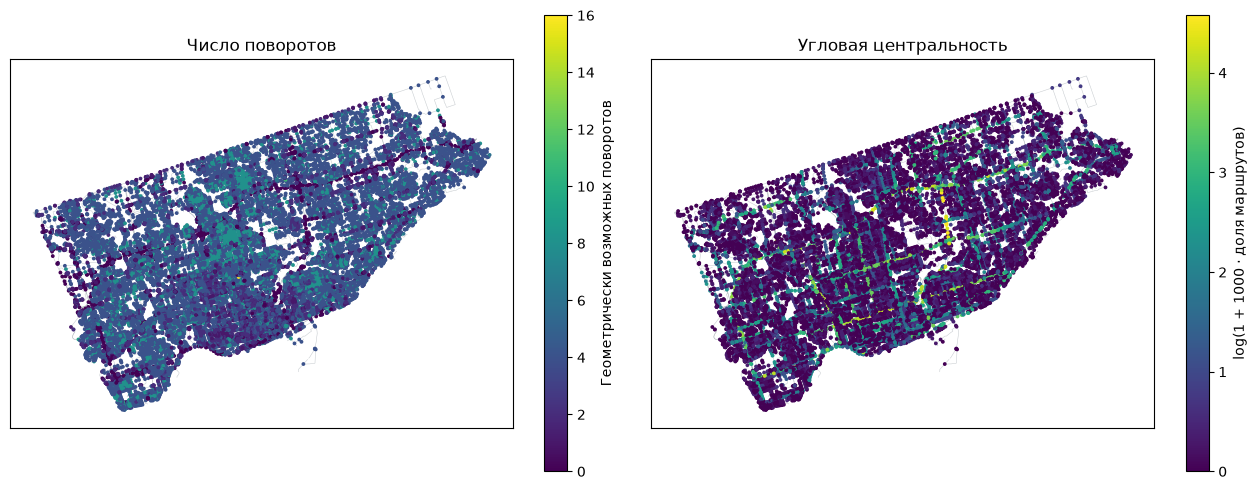

In [9]:
# собираем линии дорог для карт, обратные направления повторно не рисуем
road_lines = []
seen = set()
for u, v, data in G.edges(data=True):
    pair = frozenset((u, v))
    if pair in seen:
        continue
    seen.add(pair)
    geometry = data.get("geometry")
    points = (np.asarray(geometry.coords) if hasattr(geometry, "coords")
              else np.array([[G.nodes[u]["x"], G.nodes[u]["y"]],
                             [G.nodes[v]["x"], G.nodes[v]["y"]]]))
    if len(points) >= 2:
        road_lines.append(points)


# одна функция для фона всех OSM-карт
def draw_roads(ax):
    ax.add_collection(LineCollection(road_lines, colors="#7d8790", linewidths=0.4,
                                     alpha=0.4, zorder=0, rasterized=True))
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


# сначала посмотрим, как распределены оба признака по городу
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, values, title, label in zip(
    axes, [T_turn, angular_feature],
    ["Число поворотов", "Угловая центральность"],
    ["Геометрически возможных поворотов", "log(1 + 1000 · доля маршрутов)"]
):
    draw_roads(ax)
    dots = ax.scatter(X_all[:, 0], X_all[:, 1], c=values, s=3,
                      cmap="viridis", rasterized=True)
    fig.colorbar(dots, ax=ax, label=label)
    ax.set_title(title)
plt.tight_layout()
fig.savefig(DATA_DIR / "toronto_two_turn_features_osm_roads.png", dpi=200)
plt.show()

## Пространственная модель кокригинга

По конспекту для стационарной ковариации $\gamma(h)=C(0)-C(h)$. Используем экспоненциальную модель и одно структурное слагаемое линейной модели корегионализации:

$$C(h)=B\,e^{-h/a},\qquad
B=\begin{pmatrix}B_{ZZ}&B_{ZT}\\B_{ZT}&B_{TT}\end{pmatrix},\quad a>0.$$

Матрица $B$ должна быть симметричной и неотрицательно определенной. Для матрицы $2\times2$ это означает $B_{ZZ}\ge0$, $B_{TT}\ge0$, $B_{ZZ}B_{TT}-B_{ZT}^2\ge0$. В коде добавляем небольшую диагональную поправку и проверяем строго положительную определенность.

Для обычного кокригинга используем ограничения несмещенности:

$$\sum_i\lambda_i=1,\qquad \sum_j\beta_j=0.$$

В систему также входят два множителя Лагранжа $\eta$ и $\xi$:

$$
\begin{pmatrix}
C_{ZZ}&C_{ZT}&\mathbf 1&0\\
C_{ZT}^{\mathsf T}&C_{TT}&0&\mathbf 1\\
\mathbf 1^{\mathsf T}&0&0&0\\
0&\mathbf 1^{\mathsf T}&0&0
\end{pmatrix}
\begin{pmatrix}\lambda\\\beta\\\eta\\\xi\end{pmatrix}
=
\begin{pmatrix}c_Z\\c_T\\1\\0\end{pmatrix}.
$$

Здесь $C_{ZZ}$, $C_{ZT}$, $C_{TT}$ - ковариационные блоки, а $c_Z$, $c_T$ - ковариации наблюдений с точкой прогноза $x_0$ ($\mathbf 1$ - вектор из единиц соответствующей размерности).

**Допущения:** считаем средние постоянными, а пространственную зависимость - стационарной и изотропной. Кроме того, измерения интенсивности получены в разные даты.

In [10]:
# подбираем пространственный масштаб a по известной интенсивности Z
def fit_primary(indices):
    X_z = X_all[node_observed[indices]]
    Z = Z_observed[indices]
    # стандартизируем Z, т.к. исходные значения измеряются тысячами автомобилей
    mean, std = Z.mean(), Z.std(ddof=1)
    assert std > 0
    z = (Z - mean) / std

    # выбираем случайные пары измерений для экспериментальной полувариограммы
    rng_pairs = np.random.default_rng(1000 + len(indices))
    i = rng_pairs.integers(0, len(indices), 8000)
    j = rng_pairs.integers(0, len(indices), 8000)
    # не берем пару точки самой с собой
    different = i != j
    d = np.linalg.norm(X_z[i[different]] - X_z[j[different]], axis=1)
    # полувариограмма: 1/2 * (разность значений)^2
    gamma = 0.5 * (z[i[different]] - z[j[different]]) ** 2
    # задаем границы поиска a по расстояниям между измерениями
    p10, p90 = np.percentile(d, [10, 90])
    lower = max(50, p10 / 2)
    upper = max(2 * lower, 2 * p90)

    # ищем a, при котором модель 1 - exp(-h/a) ближе к полувариограмме
    result = minimize_scalar(
        lambda a: np.mean((gamma - (1 - np.exp(-d / a))) ** 2),
        bounds=(lower, upper), method="bounded"
    )
    a = float(result.x)
    assert result.success and np.isfinite(a) and a > 0
    return X_z, z, mean, std, a


# приводим вспомогательный признак к сопоставимому масштабу
def standardize(values):
    std = values.std(ddof=1)
    assert np.isfinite(values).all() and std > 0
    return (values - values.mean()) / std


# матрица B содержит дисперсии Z, T и их взаимную ковариацию
def covariance_B(z, t_observed):
    B = np.cov(np.vstack([z, t_observed])) + 1e-6 * np.eye(2)
    # проверяем ограничения на ковариационную матрицу
    assert np.isfinite(B).all() and np.allclose(B, B.T)
    assert B[0, 0] > 0 and B[1, 1] > 0
    assert B[0, 0] * B[1, 1] - B[0, 1] ** 2 > 0
    assert np.linalg.eigvalsh(B).min() > 0
    return B

In [11]:
# вспомогательный признак известен на всех перекрестках
tree_t = cKDTree(X_all)


def predict(x, tree_z, X_z, z, t, B, a, use_t=True, check=False):
    """обычный кригинг или кокригинг: возвращает оценку и дисперсию ошибки"""
    # выбираем ближайшие точки с измерениями интенсивности
    iz = np.atleast_1d(tree_z.query(x, k=min(K_Z, len(X_z)))[1])
    xx = X_z[iz]
    nz = len(iz)
    # ковариации между измерениями Z и с точкой прогноза
    Czz = B[0, 0] * np.exp(-cdist(xx, xx) / a)
    cz = B[0, 0] * np.exp(-cdist(xx, np.atleast_2d(x)).ravel() / a)

    # для кокригинга добавляем ковариации со вспомогательной переменной
    if use_t:
        it = np.atleast_1d(tree_t.query(x, k=min(K_T, len(X_all)))[1])
        yy = X_all[it]
        nt = len(it)
        Czt = B[0, 1] * np.exp(-cdist(xx, yy) / a)
        Ctt = B[1, 1] * np.exp(-cdist(yy, yy) / a)
        ct = B[0, 1] * np.exp(-cdist(yy, np.atleast_2d(x)).ravel() / a)
        # собираем систему кокригинга с двумя условиями несмещенности
        K = np.block([
            [Czz, Czt, np.ones((nz, 1)), np.zeros((nz, 1))],
            [Czt.T, Ctt, np.zeros((nt, 1)), np.ones((nt, 1))],
            [np.ones((1, nz)), np.zeros((1, nt)), np.zeros((1, 2))],
            [np.zeros((1, nz)), np.ones((1, nt)), np.zeros((1, 2))],
        ])
        rhs = np.r_[cz, ct, 1., 0.]
    # обычный кригинг: только Z и одно условие суммы весов
    else:
        K = np.block([[Czz, np.ones((nz, 1))],
                      [np.ones((1, nz)), np.zeros((1, 1))]])
        rhs = np.r_[cz, 1.]

    # решаем систему, получаем веса и множители Лагранжа
    weights = np.linalg.solve(K, rhs)
    lambda_z = weights[:nz]
    eta = weights[-2] if use_t else weights[-1]
    
    # первая сумма в оценке: веса * известная интенсивность
    estimate = z[iz] @ lambda_z
    variance = B[0, 0] - lambda_z @ cz - eta

    if use_t:
        beta = weights[nz:nz + nt]
        
        # вторая сумма в кокригинге: веса * вспомогательный признак
        estimate += t[it] @ beta
        variance -= beta @ ct

    # проверяем условия несмещенности для каждого прогноза
    assert abs(lambda_z.sum() - 1) < 1e-6
    if use_t:
        assert abs(beta.sum()) < 1e-6
    assert variance >= -1e-6

    # дополнительные проверки самой системы включаем только для части точек
    if check:
        assert np.allclose(K, K.T, atol=1e-9)
        assert np.max(np.abs(K @ weights - rhs)) < 1e-6
        if np.linalg.cond(K) > 1e12:
            print("Предупреждение: локальная система плохо обусловлена")

    return float(estimate), float(max(variance, 0))


# MAE - средняя абсолютная ошибка, RMSE сильнее штрафует за большие ошибки
def metrics(actual, estimated):
    return np.mean(np.abs(actual - estimated)), np.sqrt(np.mean((actual - estimated) ** 2))

## Проверка точности и выбор вспомогательного признака

### Связь признаков с интенсивностью

Перед прогнозированием посмотрим, есть ли связь между интенсивностью $Z$ и рассчитанными признаками $T_1$ и $T_2$. Для этого вычислим корреляции Пирсона и Спирмена на обучающих данных.

По одной корреляции нельзя определить, улучшится ли кокригинг, т.к. метод использует еще и пространственные ковариации.

In [12]:
# для корреляций берем только точки с обучающими измерениями
X_train = X_all[node_observed[train_idx]]
Z_train = Z_observed[train_idx]

rows = []
for name, values in features.items():
    values_train = values[node_observed[train_idx]]
    # корреляция не определена, если признак везде одинаковый
    if np.std(values_train) > 0:
        pearson = np.corrcoef(Z_train, values_train)[0, 1]
        spearman = spearmanr(Z_train, values_train).statistic
    else:
        pearson, spearman = np.nan, np.nan
    rows.append([name, pearson, spearman, len(np.unique(values_train))])
correlations = pd.DataFrame(rows, columns=[
    "Признак", "Пирсон", "Спирмен", "Различных значений"
]).set_index("Признак")
display(correlations.round(3))

,Пирсон,Спирмен,Различных значений
Признак,,,
Число поворотов,-0.152,-0.119,12
Угловая центральность,0.379,0.471,235


### Внутренняя проверка вариантов прогноза

Чтобы выбрать вспомогательный признак, сравним ошибки обычного кригинга и кокригинга с $T_1$ и $T_2$. Все варианты проверяются на одинаковых точках. Критерий выбора признака - средняя MAE на внутренних проверках.

In [13]:
# заранее стандартизируем оба вспомогательных признака
standardized_features = {name: standardize(values) for name, values in features.items()}
validation_size = min(VALIDATION_SIZE, len(train_idx) // 3)
assert validation_size >= 5

rows = []
# несколько раз делим обучающие измерения на расчетную и проверочную части
for repeat in range(REPEATS):
    shuffled = np.random.default_rng(SEED + 100 + repeat).permutation(train_idx)
    fit_idx = shuffled[validation_size:]
    valid_idx = shuffled[:validation_size]

    # подбираем a только по расчетной части, чтобы не использовать ответы проверки
    X_fit, z_fit, mean, std, a = fit_primary(fit_idx)
    tree_z = cKDTree(X_fit)
    X_valid = X_all[node_observed[valid_idx]]
    Z_valid = Z_observed[valid_idx]

    # сначала прогнозируем обычным кригингом без T
    pred_k = np.array([
        predict(x, tree_z, X_fit, z_fit, None, np.eye(2), a, use_t=False)[0]
        for x in X_valid
    ]) * std + mean
    mae_k, rmse_k = metrics(Z_valid, pred_k)
    rows.append([repeat + 1, "Кригинг", mae_k, rmse_k])

    # затем повторяем прогноз с каждым вариантом T
    for name, t in standardized_features.items():
        B = covariance_B(z_fit, t[node_observed[fit_idx]])
        pred_ck = np.array([
            predict(x, tree_z, X_fit, z_fit, t, B, a)[0]
            for x in X_valid
        ]) * std + mean
        mae, rmse = metrics(Z_valid, pred_ck)
        rows.append([repeat + 1, name, mae, rmse])

# усредняем ошибки по повторам и смотрим, дает ли T улучшение
cv_results = pd.DataFrame(rows, columns=["Повтор", "Модель", "MAE", "RMSE"])
cv_summary = cv_results.groupby("Модель")[["MAE", "RMSE"]].mean()
cv_summary["ΔMAE к кригингу"] = cv_summary["MAE"] - cv_summary.loc["Кригинг", "MAE"]
print("Внутренние проверки (отрицательная ΔMAE означает улучшение):")
display(cv_summary.sort_values("MAE").round(2))

Внутренние проверки (отрицательная ΔMAE означает улучшение):


,MAE,RMSE,ΔMAE к кригингу
Модель,,,
Угловая центральность,7113.13,9654.70,-1264.84
Кригинг,8377.97,11117.50,0.00
Число поворотов,8672.97,11252.99,295.00


### Оценка точности на контрольной выборке

Проверим полученные прогнозы на 25% измеренных перекрестков, которые не использовались при обучении в данном разбиении. Сначала посчитаем MAE и RMSE по исходным прогнозам, а затем отдельно проверим погрешности после замены отрицательных прогнозов нулями

In [14]:
# теперь проверяем качество на отложенных 25% измерений
X_fit, z_fit, mean, std, a = fit_primary(train_idx)
tree_z = cKDTree(X_fit)
X_test = X_all[node_observed[test_idx]]
Z_test = Z_observed[test_idx]

# обычный кригинг нужен как базовый вариант без вспомогательных данных
pred_test = {
    "Кригинг": np.array([
        predict(x, tree_z, X_fit, z_fit, None, np.eye(2), a, use_t=False, check=(i < 10))[0]
        for i, x in enumerate(X_test)
    ]) * std + mean
}

# оцениваем оба варианта кокригинга на тех же контрольных точках
for name, t in standardized_features.items():
    B = covariance_B(z_fit, t[node_observed[train_idx]])
    pred_test[name] = np.array([
        predict(x, tree_z, X_fit, z_fit, t, B, a, check=(i < 10))[0]
        for i, x in enumerate(X_test)
    ]) * std + mean

# сравниваем MAE, RMSE и число отрицательных прогнозов
rows = []
for name, values in pred_test.items():
    mae, rmse = metrics(Z_test, values)
    rows.append([name, mae, rmse, int((values < 0).sum())])

holdout_scores = pd.DataFrame(rows, columns=[
    "Модель", "MAE", "RMSE", "Отрицательных прогнозов"
]).set_index("Модель")
holdout_scores["ΔMAE к кригингу"] = (
    holdout_scores["MAE"] - holdout_scores.loc["Кригинг", "MAE"]
)
print("Контроль на", len(test_idx), "отложенных перекрестках:")
display(holdout_scores.sort_values("MAE").round(2))

Контроль на 590 отложенных перекрестках:


,MAE,RMSE,Отрицательных прогнозов,ΔMAE к кригингу
Модель,,,,
Угловая центральность,7160.45,9886.65,1,-1081.93
Кригинг,8242.38,11287.24,2,0.00
Число поворотов,8559.99,11412.35,9,317.61


### Абсолютные и относительные погрешности

MAE и RMSE выше рассчитаны до замены отрицательных прогнозов нулями. На итоговой карте используется $\widehat Z_i=\max(\widehat Z_i^{\mathrm{raw}},0)$, поэтому отдельно оценим точность именно таких значений.

Для каждого контрольного перекрестка, где известно реальное значение $Z_i>0$, считаем:

$$\Delta_i=|Z_i-\widehat Z_i|,\qquad \delta_i=\frac{\Delta_i}{Z_i}\cdot100\%. $$

Обобщенные показатели:

$$\mathrm{MAE}=\frac1N\sum_i\Delta_i,\qquad
\mathrm{MSE}=\frac1N\sum_i(Z_i-\widehat Z_i)^2,\qquad
\mathrm{RMSE}=\sqrt{\mathrm{MSE}},$$

$$\mathrm{MAPE}=\frac1N\sum_i\delta_i,\qquad
\mathrm{WAPE}=\frac{\sum_i\Delta_i}{\sum_i Z_i}\cdot100\%. $$

MAE и RMSE измеряются в автомобилях за 14 часов, MSE - в квадратах этих единиц, а MAPE и WAPE - в процентах. MAPE может сильно увеличиваться из-за перекрестков с небольшим потоком, поэтому дополнительно показываем WAPE.

Еще одна величина - расчетная дисперсия ошибки кокригинга $\sigma^2(x)$ из ковариационной модели. Ее квадратный корень $\sigma(x)$ имеет единицы автомобилей за 14 часов, но не является фактической погрешностью.

Погрешности на 590 контрольных перекрестках (после отсечения отрицательных прогнозов):


,MAE,MSE,RMSE,"MAPE, %","WAPE, %",Медиана абсолютной,90% квантиль абсолютной
Модель,,,,,,,
Угловая центральность,7160.37,9.774548e+07,9886.63,91.42,37.89,4960.40,17433.50
Кригинг,8238.91,1.273751e+08,11286.06,116.54,43.59,5610.33,19448.16
Число поворотов,8540.03,1.300466e+08,11403.80,123.05,45.19,6168.36,19120.41


Выбранный признак: Угловая центральность
Среднее реальное значение: 18899.6 автомобилей за 14 часов
Средняя расчетная σ: 4189.2 автомобилей
Максимальная абсолютная ошибка: 43348.5 автомобилей


,osm_node_id,real_14h_vehicles,predicted_14h_vehicles,absolute_error,relative_error_percent,cokriging_variance,cokriging_std_vehicles
292,72302964,63913.0,20564.51,43348.49,67.82,20009646.76,4473.21
202,23845494,43497.0,9755.32,33741.68,77.57,21259617.29,4610.82
184,20650056,12600.0,45341.69,32741.69,259.85,29285083.74,5411.57
460,261632665,25712.0,56755.07,31043.07,120.73,35525593.39,5960.34
306,3461644,44335.0,13598.76,30736.24,69.33,16094256.34,4011.76
328,427965453,54144.0,24847.77,29296.23,54.11,41808418.58,6465.94
148,61568959,3224.0,32383.12,29159.12,904.44,30905918.56,5559.31
573,390371917,66821.0,39278.51,27542.49,41.22,20976364.87,4580.00
258,32474412,8378.0,34078.04,25700.04,306.76,6764298.13,2600.83
87,303450631,39678.0,14190.43,25487.57,64.24,23155137.13,4811.98


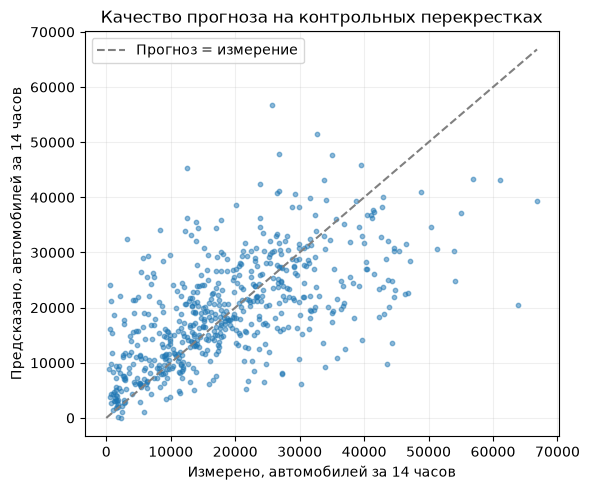

In [15]:
# для итоговой карты отрицательные прогнозы заменяем нулями
# проверим точность после такого же преобразования на контрольных точках
rows = []
for name, raw_values in pred_test.items():
    values = np.maximum(raw_values, 0)
    errors = values - Z_test
    absolute = np.abs(errors)
    relative = 100 * absolute / Z_test

    rows.append([
        name,
        absolute.mean(),
        np.mean(errors ** 2),
        np.sqrt(np.mean(errors ** 2)),
        relative.mean(),
        100 * absolute.sum() / Z_test.sum(),
        np.median(absolute),
        np.quantile(absolute, 0.9),
    ])

error_summary = pd.DataFrame(rows, columns=[
    "Модель", "MAE", "MSE", "RMSE", "MAPE, %", "WAPE, %",
    "Медиана абсолютной", "90% квантиль абсолютной"
]).set_index("Модель")
print("Погрешности на", len(Z_test), "контрольных перекрестках (после отсечения отрицательных прогнозов):")
display(error_summary.sort_values("MAE").round(2))

# подробная таблица погрешностей для выбранного варианта кокригинга
best_name = cv_summary.loc[list(features), "MAE"].idxmin()
best_raw = pred_test[best_name]
best_pred = np.maximum(best_raw, 0)
absolute = np.abs(best_pred - Z_test)

# дополнительно рассчитываем теоретическую дисперсию ошибки из системы кокригинга
best_t = standardized_features[best_name]
B_best = covariance_B(z_fit, best_t[node_observed[train_idx]])
model_variance = np.array([
    predict(x, tree_z, X_fit, z_fit, best_t, B_best, a)[1]
    for x in X_test
]) * std ** 2

error_details = pd.DataFrame({
    "osm_node_id": np.asarray(node_ids)[node_observed[test_idx]],
    "real_14h_vehicles": Z_test,
    "predicted_14h_vehicles": best_pred,
    "absolute_error": absolute,
    "relative_error_percent": 100 * absolute / Z_test,
    "cokriging_variance": model_variance,
    "cokriging_std_vehicles": np.sqrt(np.maximum(model_variance, 0)),
})
error_summary.to_csv(DATA_DIR / "toronto_error_summary.csv")
error_details.to_csv(DATA_DIR / "toronto_control_errors.csv", index=False)

print("Выбранный признак:", best_name)
print("Среднее реальное значение:", round(float(Z_test.mean()), 1), "автомобилей за 14 часов")
print("Средняя расчетная σ:", round(float(error_details["cokriging_std_vehicles"].mean()), 1), "автомобилей")
print("Максимальная абсолютная ошибка:", round(float(absolute.max()), 1), "автомобилей")
display(error_details.sort_values("absolute_error", ascending=False).head(10).round(2))

# на диагонали прогноз равен реальному значению
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(Z_test, best_pred, s=10, alpha=0.5)
limit = max(float(Z_test.max()), float(best_pred.max()))
ax.plot([0, limit], [0, limit], "--", color="gray", label="Прогноз = измерение")
ax.set(xlabel="Измерено, автомобилей за 14 часов",
       ylabel="Предсказано, автомобилей за 14 часов",
       title="Качество прогноза на контрольных перекрестках")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Проверка ковариационной модели

Для обоих вспомогательных признаков построим экспериментальные полувариограммы $\gamma_{ZZ}$, $\gamma_{TT}$ и взаимную $\gamma_{ZT}$, затем сравним их с моделью $C(h)=Be^{-h/a}$.

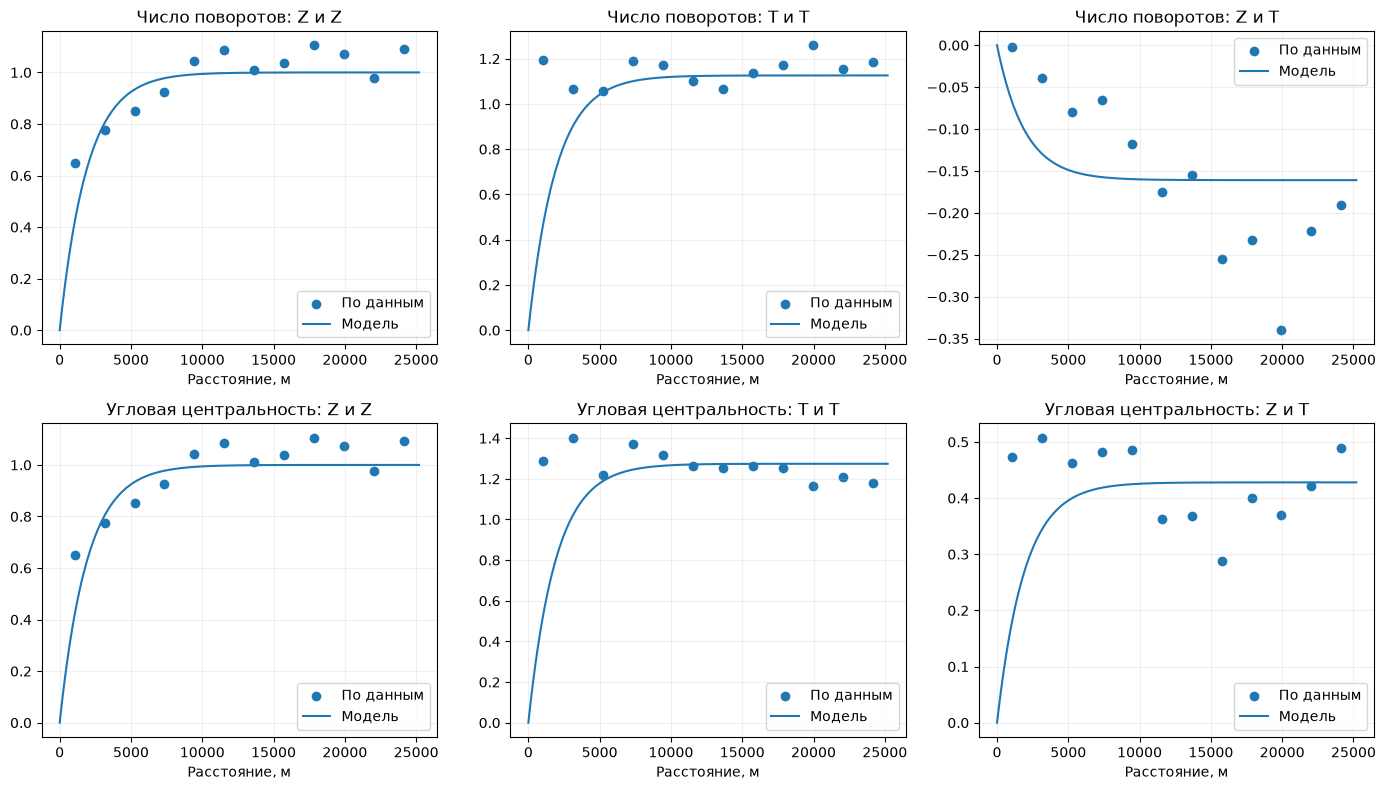

In [16]:
# отдельно проверяем, насколько ковариационная модель соответствует данным
rng_pairs = np.random.default_rng(900)
i = rng_pairs.integers(0, len(train_idx), 10000)
j = rng_pairs.integers(0, len(train_idx), 10000)
keep = i != j
i, j = i[keep], j[keep]
d = np.linalg.norm(X_fit[i] - X_fit[j], axis=1)
# разности Z в парах точек для полувариограммы
dz = z_fit[i] - z_fit[j]
bins = np.linspace(0, np.percentile(d, 95), 13)

# для каждого T строим три графика: Z-Z, T-T и Z-T
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, (name, t) in enumerate(standardized_features.items()):
    t_observed = t[node_observed[train_idx]]
    dt = t_observed[i] - t_observed[j]
    B = covariance_B(z_fit, t_observed)
    # первые два выражения - полувариограммы, третье - взаимная
    gamma_values = [0.5 * dz ** 2, 0.5 * dt ** 2, 0.5 * dz * dt]
    coeffs = [B[0, 0], B[1, 1], B[0, 1]]

    for ax, gamma, coeff, label in zip(
        axes[row], gamma_values, coeffs, ["Z и Z", "T и T", "Z и T"]
    ):
        centers, values = [], []
        # усредняем значения в интервалах расстояний
        for left, right in itertools.pairwise(bins):
            group = (d >= left) & (d < right)
            if group.sum() >= 30:
                centers.append((left + right) / 2)
                values.append(gamma[group].mean())
        r = np.linspace(0, bins[-1], 200)
        ax.scatter(centers, values, label="По данным")
        # поверх экспериментальных точек рисуем экспоненциальную модель
        ax.plot(r, coeff * (1 - np.exp(-r / a)), label="Модель")
        ax.set(xlabel="Расстояние, м", title=f"{name}: {label}")
        ax.grid(alpha=0.2)
        ax.legend()
plt.tight_layout()
plt.show()

## Восстановление интенсивности на всех перекрестках

На внутренних проверках выбираем вспомогательный признак с меньшей MAE. После оценки точности используем все доступные измерения для итогового восстановления интенсивности на перекрестках без измерений.

В точках с известной интенсивностью модель без самородка должна воспроизводить измерения с небольшой численной погрешностью. В остальных точках получаем прогноз и оценку его дисперсии.

In [17]:
# после проверки используем все измерения для итогового прогноза
X_full, z_full, z_mean, z_std, a_full = fit_primary(np.arange(len(Z_observed)))
tree_z_full = cKDTree(X_full)
# выбираем T с минимальной средней MAE на внутренних проверках
best_name = cv_summary.loc[list(features), "MAE"].idxmin()
print("Выбранный вспомогательный признак:", best_name)
t_full = standardized_features[best_name]
# заново оцениваем ковариационную матрицу по всем измерениям
B_full = covariance_B(z_full, t_full[node_observed])

print("a =", round(a_full, 2), "м")
print("B =\n", B_full)

# для каждого перекрестка сохраняем прогноз и дисперсию ошибки
raw_preds = np.empty(len(X_all))
variance = np.empty(len(X_all))
for i, x in enumerate(X_all):
    estimate, var = predict(x, tree_z_full, X_full, z_full, t_full,
                            B_full, a_full, check=(i < 10))
    # переводим стандартизированный прогноз обратно в автомобили за 14 часов
    raw_preds[i] = estimate * z_std + z_mean
    # дисперсия при обратной стандартизации умножается на квадрат std
    variance[i] = var * z_std ** 2
    if (i + 1) % 5000 == 0:
        print("Прогнозов:", i + 1, "из", len(X_all))

assert np.isfinite(raw_preds).all() and np.isfinite(variance).all()
assert (variance >= 0).all()
# проверяем, что в точках измерений модель воспроизводит известные значения
error_on_observed = np.max(np.abs(raw_preds[node_observed] - Z_observed))
assert error_on_observed < 1e-3, "Проверьте интерполяцию в точках измерений"

# отрицательная интенсивность невозможна => для карты заменяем ее нулем
preds = np.maximum(raw_preds, 0)
measured = np.zeros(len(node_ids), dtype=bool)
measured[node_observed] = True

# возвращаем координаты в долготу и широту для итоговой таблицы
back = Transformer.from_crs(G.graph["crs"], "EPSG:4326", always_xy=True)
lon, lat = back.transform(X_all[:, 0], X_all[:, 1])

predictions = pd.DataFrame({
    "osm_node_id": node_ids,
    "x_m": X_all[:, 0], "y_m": X_all[:, 1],
    "longitude": lon, "latitude": lat,
    "turn_potential": T_turn,
    "angular_centrality": angular_feature,
    "predicted_14h_vehicles": preds,
    "raw_predicted_14h_vehicles": raw_preds,
    "cokriging_variance": variance,
    "has_real_count": measured,
})
suffix = "angular" if best_name == "Угловая центральность" else "turns"
output_csv = DATA_DIR / f"toronto_all_intersections_{suffix}_cokriging.csv"
predictions.to_csv(output_csv, index=False)
print("Проверка в измеренных точках, макс. ошибка:", round(error_on_observed, 6))
print("Отрицательных прогнозов до отсечения:", int((raw_preds < 0).sum()))

Выбранный вспомогательный признак: Угловая центральность
a = 1946.38 м
B =
 [[1.000001   0.4450108 ]
 [0.4450108  1.26971382]]
Прогнозов: 5000 из 22354
Прогнозов: 10000 из 22354
Прогнозов: 15000 из 22354
Прогнозов: 20000 из 22354
Проверка в измеренных точках, макс. ошибка: 0.0
Отрицательных прогнозов до отсечения: 72


## Карта интенсивности движения

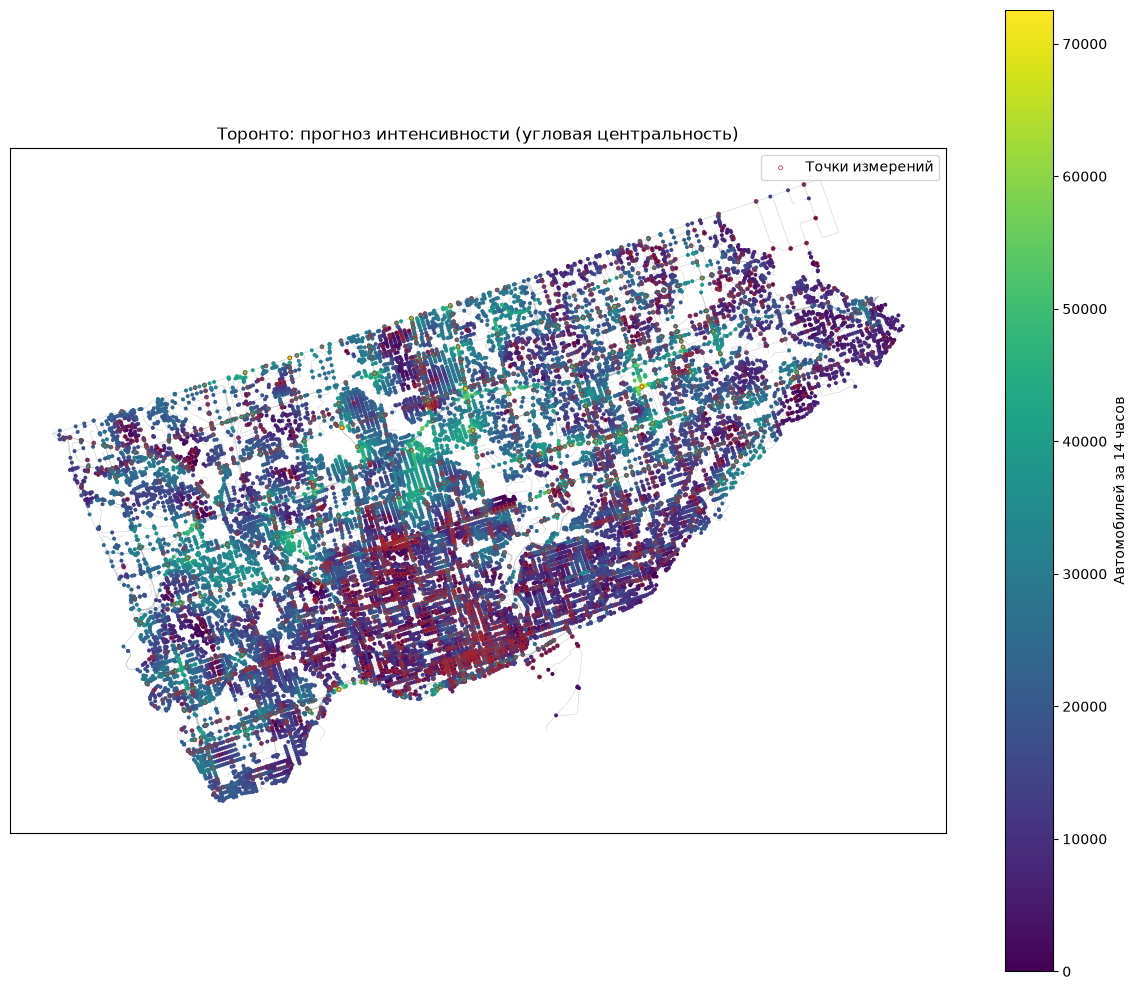

In [18]:
fig, ax = plt.subplots(figsize=(12, 10))
draw_roads(ax)
dots = ax.scatter(X_all[:, 0], X_all[:, 1], c=preds, s=3.5,
                  cmap="viridis", vmin=0, vmax=float(preds.max()), rasterized=True, zorder=2)

ax.scatter(X_all[node_observed, 0], X_all[node_observed, 1], s=8,
           facecolors="none", edgecolors="firebrick", linewidths=0.5,
           zorder=3, label="Точки измерений")
fig.colorbar(dots, ax=ax, label="Автомобилей за 14 часов")
ax.set_title(f"Торонто: прогноз интенсивности ({best_name.lower()})")
ax.legend()
plt.tight_layout()
fig.savefig(DATA_DIR / f"toronto_intersections_{suffix}_cokriging_osm_roads.png", dpi=220)
plt.show()

### Перекрестки с наибольшей интенсивностью

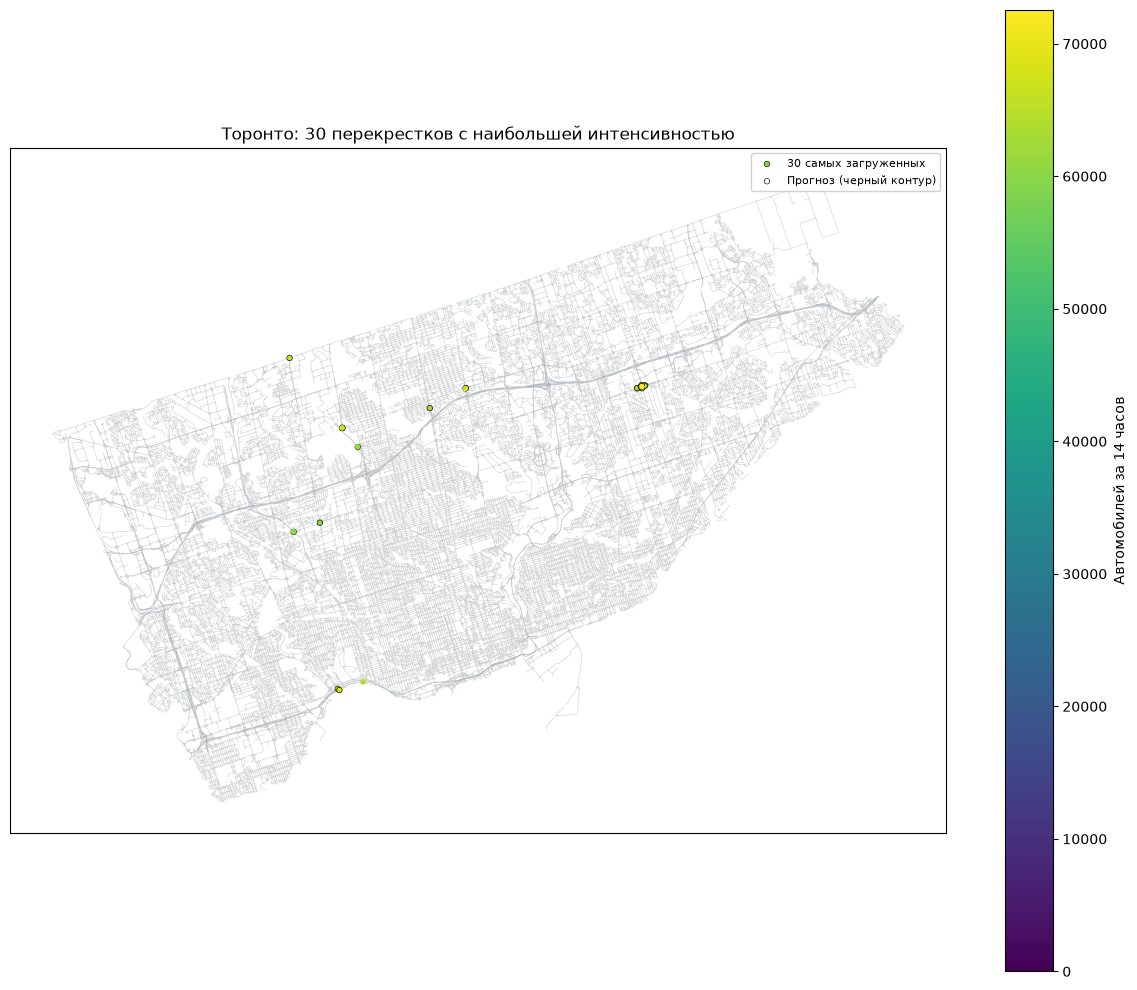

Топ-30: измерений - 8 , прогнозов - 22
Порог попадания в топ-30: 59560.2 автомобилей за 14 часов
Карта: data/toronto_top_30_intersections_osm.png


,osm_node_id,predicted_14h_vehicles,Тип значения,longitude,latitude
17556,414457836,72545.00,Измерение,-79.28,43.77
5501,469705498,71860.12,Прогноз,-79.28,43.77
21693,469705522,71857.96,Прогноз,-79.28,43.77
21691,469705515,71272.12,Прогноз,-79.28,43.77
21690,469705486,69145.67,Прогноз,-79.28,43.77
13153,262267320,67775.77,Прогноз,-79.47,43.63
22045,1721194521,67593.00,Измерение,-79.46,43.75
15400,291608248,67310.39,Прогноз,-79.49,43.78
21898,1721194475,67228.43,Прогноз,-79.46,43.75
21687,469705491,67165.49,Прогноз,-79.28,43.77


In [20]:
TOP_N = 30
hot = predictions.nlargest(TOP_N, "predicted_14h_vehicles").copy()

# по наличию измерения определяем, где значение известно, а где предсказано
measured = hot["has_real_count"].astype(str).str.lower().eq("true")
hot["Тип значения"] = np.where(measured, "Измерение", "Прогноз")
hot.to_csv(DATA_DIR / "toronto_top_30_intersections.csv", index=False)

# более интенсивные точки рисуем последними, чтобы они были сверху
hot_plot = hot.sort_values("predicted_14h_vehicles")
edge_colors = np.where(
    hot_plot["Тип значения"] == "Прогноз", "black", "none"
)

# на фоне оставляем все перекрестки и дороги, цветом выделяем только топ-30
fig, ax = plt.subplots(figsize=(12, 10))
draw_roads(ax)

ax.scatter(X_all[:, 0], X_all[:, 1], s=2, c="lightgray",
           alpha=0.45, linewidths=0, rasterized=True, zorder=2)

points = ax.scatter(
    hot_plot["x_m"], hot_plot["y_m"],
    c=hot_plot["predicted_14h_vehicles"], cmap="viridis",
    vmin=0, vmax=float(preds.max()),
    s=16, edgecolors=edge_colors, linewidths=0.45,
    zorder=3, rasterized=True, label="30 самых загруженных"
)

ax.scatter([], [], s=16, facecolors="none", edgecolors="black",
           linewidths=0.45, label="Прогноз (черный контур)")
fig.colorbar(points, ax=ax, label="Автомобилей за 14 часов")
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Торонто: 30 перекрестков с наибольшей интенсивностью")
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout()

map_file = DATA_DIR / "toronto_top_30_intersections_osm.png"
fig.savefig(map_file, dpi=220, bbox_inches="tight")
plt.show()

print("Топ-30: измерений -", int(measured.sum()),
      ", прогнозов -", int((~measured).sum()))
print("Порог попадания в топ-30:",
      round(float(hot["predicted_14h_vehicles"].min()), 1),
      "автомобилей за 14 часов")
print("Карта:", map_file)
display(hot[["osm_node_id", "predicted_14h_vehicles", "Тип значения",
             "longitude", "latitude"]].head(10).round(2))

## Результаты и выводы

В ходе подготовки коррелирующей переменной рассмотрены два признака: число геометрически возможных поворотов $T_1$ и угловая центральность $T_2$. Их проверка показала, что для текущего набора данных угловая центральность полезнее при прогнозировании интенсивности, поэтому она использована в итоговом кокригинге.

**Результаты выполненного расчета:**

| Вариант прогноза | MAE | RMSE |
|---|---:|---:|
| Обычный кригинг | 8242,38 | 11287,24 |
| Кокригинг с числом поворотов | 8559,99 | 11412,35 |
| Кокригинг с угловой центральностью | 7160,45 | 9886,65 |

Ошибки в таблице указаны в автомобилях за 14 часов на 590 контрольных перекрестках до отсечения отрицательных прогнозов. В разделе 4.4 дополнительно вычислены абсолютные и относительные погрешности (MAE, MSE, RMSE, MAPE, WAPE) после отсечения, как на итоговой карте. Расчетная дисперсия ошибки кокригинга рассматривается отдельно от фактических ошибок. По сравнению с обычным кригингом использование угловой центральности уменьшило MAE примерно на 13,1%. Число поворотов в этом эксперименте точность не улучшило.

После выбора признака модель построена по всем 2359 измерениям, а интенсивность восстановлена для 22 354 перекрестков OSM. На итоговой карте выделены 30 перекрестков с наибольшими значениями: 8 с измерениями и 22 с прогнозами.

**Проверки математических ограничений:**

| Условие | Как проверяем |
|---|---|
| $\sum_i\lambda_i=1$ | При каждом прогнозе |
| $\sum_j\beta_j=0$ | При каждом прогнозе кокригинга |
| $B=B^{\mathsf T}$, $B\succ0$ | Симметрия, определитель и собственные значения |
| $a>0$ | После подбора пространственного масштаба |
| $Kw=b$ | Невязка на первых десяти контрольных точках каждого метода |
| $D\ge0$ | При каждом прогнозе с численным допуском |
| Сопоставление с OSM | Расстояние не более 45 м, без повторных узлов |

**Ограничения результата.** Измерения сделаны в разные даты, а ковариационная модель предполагает постоянство средних, стационарность и изотропность. Число поворотов не учитывает все запреты маневров; угловая центральность зависит от выборки маршрутов. Одна экспоненциальная структура (B) может не описывать все пространственные зависимости одинаково хорошо. В итоговой выгрузке отрицательные прогнозы заменены нулями, исходные значения сохранены отдельно